# SVM — Thyroid Classification

Support vector machine on the thyroid data, with an RBF kernel.

Two things an SVM needs that the tree models did not:

- **Scaling.** The kernel measures distance between patients, and TSH runs to 530 while T4U sits
  near 1. Unscaled, TSH would be the only feature the kernel can see.
- **No missing values.** `NaN` has no distance, so the gaps must be filled. Median imputation goes
  inside a pipeline, so the median comes from the training fold rather than leaking the
  full-dataset value into the test set.

**Carried forward:** TSH needs a `log1p` transform. It spans 0.005 to 530, and the clinically
meaningful jump is multiplicative — around 6 — not additive. Section 1 shows what that transform
is worth to an SVM specifically, because it turns out to matter more here than any kernel or
hyperparameter choice.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix,
                             precision_recall_curve)

NEG, POS = "#2a78d6", "#eb6834"

## Load and clean

In [2]:
df = pd.read_csv("../dataset/cleaned_dataset_Thyroid1.csv").drop_duplicates()

for flag, value in [("TSH measured", "TSH"), ("TT4 measured", "TT4"),
                    ("T4U measured", "T4U"), ("FTI measured", "FTI")]:
    df.loc[df[flag] == 0, value] = np.nan
df.loc[~df["sex"].isin([0.0, 1.0]), "sex"] = np.nan
df = df.drop(columns=["hypopituitary"])

y = df["binaryClass"]
X_raw = df.drop(columns=["binaryClass"])

X_log = X_raw.copy()
X_log["TSH"] = np.log1p(X_log["TSH"])
X_log = X_log.rename(columns={"TSH": "log1p(TSH)"})

print(f"{len(df)} patients, {int(y.sum())} hypothyroid ({100*y.mean():.1f}%)")

3708 patients, 291 hypothyroid (7.8%)


In [3]:
# SVC has no predict_proba of its own; CalibratedClassifierCV supplies one.
# (SVC(probability=True) does the same thing but is deprecated in sklearn 1.9.)
def svm(**kwargs):
    return make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        CalibratedClassifierCV(
            SVC(class_weight="balanced", random_state=42, **kwargs), ensemble=False
        ),
    )

def evaluate(X, model, label):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    model.fit(Xtr, ytr)
    proba = model.predict_proba(Xte)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {"model": label,
            "avg_precision": round(average_precision_score(yte, proba), 4),
            "missed": int(((pred == 0) & (yte == 1)).sum()),
            "false_alarms": int(((pred == 1) & (yte == 0)).sum())}

## 1. The log transform matters more than the kernel

Same model, same hyperparameters, one column transformed.

In [4]:
pd.DataFrame([
    evaluate(X_raw, svm(), "RBF, raw TSH"),
    evaluate(X_log, svm(), "RBF, log1p(TSH)"),
]).set_index("model")

,avg_precision,missed,false_alarms
model,,,
"RBF, raw TSH",0.8408,17,4
"RBF, log1p(TSH)",0.9620,6,3


Average precision goes from 0.84 to 0.96, and missed cases drop from 17 to 6, on one `log1p`.
Nothing else in this notebook produces a gain that size. On the raw scale the kernel sees a patient
with TSH 300 as wildly distant from one with TSH 30, when both are plainly hypothyroid — the
transform makes those neighbours.

Everything below uses `log1p(TSH)`.

## 2. Kernel and C

In [5]:
pd.DataFrame([
    evaluate(X_log, svm(kernel="linear"), "linear kernel"),
    evaluate(X_log, svm(), "RBF, C=1 (default)"),
    evaluate(X_log, svm(C=10), "RBF, C=10"),
    evaluate(X_log, svm(C=100), "RBF, C=100"),
]).set_index("model")

,avg_precision,missed,false_alarms
model,,,
linear kernel,0.9524,11,2
"RBF, C=1 (default)",0.9620,6,3
"RBF, C=10",0.9681,7,3
"RBF, C=100",0.9695,8,4


The linear kernel is only marginally behind the RBF, which says the classes are close to linearly
separable once TSH is logged — consistent with the decision tree finding a single clean threshold.
Raising `C` trades recall for precision: fewer false alarms, more missed patients.

### Grid search

Tuned on the training folds only, scored by average precision.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_log, y, test_size=0.2, stratify=y, random_state=42
)

grid = GridSearchCV(
    svm(),
    {"calibratedclassifiercv__estimator__C": [1, 10, 100, 1000],
     "calibratedclassifiercv__estimator__gamma": ["scale", 0.01, 0.1, 1]},
    scoring="average_precision",
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    n_jobs=-1,
)
grid.fit(X_train, y_train)

print(f"best params : {grid.best_params_}")
print(f"cv AP       : {grid.best_score_:.4f}")

best params : {'calibratedclassifiercv__estimator__C': 10, 'calibratedclassifiercv__estimator__gamma': 'scale'}
cv AP       : 0.9401


## 3. Final model

In [7]:
proba = grid.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(f"test AP: {average_precision_score(y_test, proba):.4f}\n")
print(classification_report(y_test, pred, target_names=["negative", "hypothyroid"], digits=4))
print("confusion matrix [rows = actual]")
print(confusion_matrix(y_test, pred))

test AP: 0.9681

              precision    recall  f1-score   support

    negative     0.9898    0.9956    0.9927       684
 hypothyroid     0.9444    0.8793    0.9107        58

    accuracy                         0.9865       742
   macro avg     0.9671    0.9375    0.9517       742
weighted avg     0.9863    0.9865    0.9863       742

confusion matrix [rows = actual]
[[681   3]
 [  7  51]]


**Read the bottom-left cell.** At the default 0.5 cut the SVM misses 7 of 58 hypothyroid patients.
The depth-3 decision tree misses none. For a screening test that difference matters far more than
the average-precision gap.

Lowering the threshold recovers most of them:

In [8]:
pd.DataFrame([
    {"threshold": t,
     "recall": round(((proba >= t) & (y_test == 1)).sum() / (y_test == 1).sum(), 4),
     "missed": int(((proba < t) & (y_test == 1)).sum()),
     "false_alarms": int(((proba >= t) & (y_test == 0)).sum())}
    for t in [0.05, 0.10, 0.20, 0.30, 0.50]
]).set_index("threshold")

,recall,missed,false_alarms
threshold,,,
0.05,0.9828,1,42
0.10,0.9655,2,26
0.20,0.9483,3,17
0.30,0.9310,4,9
0.50,0.8793,7,3


## 4. Precision-recall curve

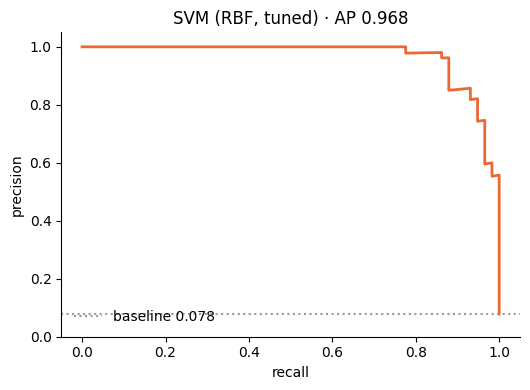

In [9]:
prec, rec, _ = precision_recall_curve(y_test, proba)

fig, ax = plt.subplots(figsize=(5.4, 4))
ax.plot(rec, prec, color=POS, linewidth=2)
ax.axhline(y_test.mean(), color="#9a9992", linestyle=":", linewidth=1.5,
           label=f"baseline {y_test.mean():.3f}")
ax.set_xlabel("recall")
ax.set_ylabel("precision")
ax.set_title(f"SVM (RBF, tuned) · AP {average_precision_score(y_test, proba):.3f}")
ax.set_ylim(0, 1.05)
ax.legend(frameon=False, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 5. What the kernel is doing

The full model works in 24 dimensions, which cannot be drawn. Refitting on just the two features
that carry the signal shows the shape of an RBF boundary — curved, unlike the tree's rectangular
cuts.

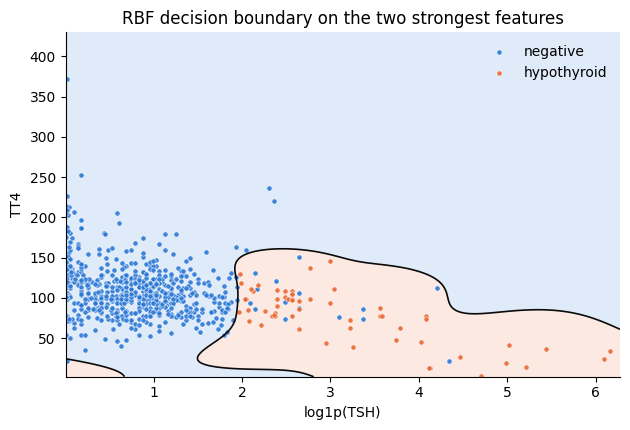

In [10]:
pair = ["log1p(TSH)", "TT4"]
Xp_train = X_train[pair]
two = svm(C=10).fit(Xp_train, y_train)

xx, yy = np.meshgrid(
    np.linspace(Xp_train[pair[0]].min(), Xp_train[pair[0]].max(), 250),
    np.linspace(np.nanmin(Xp_train[pair[1]]), np.nanmax(Xp_train[pair[1]]), 250),
)
grid_points = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=pair)
zz = two.predict_proba(grid_points)[:, 1].reshape(xx.shape)

fig, ax = plt.subplots(figsize=(6.4, 4.4))
ax.contourf(xx, yy, zz, levels=[0, 0.5, 1], colors=[NEG, POS], alpha=0.14)
ax.contour(xx, yy, zz, levels=[0.5], colors=["#0b0b0b"], linewidths=1.2)
sub = X_test[pair].copy()
for cls, colour, name in [(0, NEG, "negative"), (1, POS, "hypothyroid")]:
    m = (y_test == cls).values
    ax.scatter(sub[m][pair[0]], sub[m][pair[1]], s=14, c=colour, label=name,
               edgecolor="white", linewidth=0.4, alpha=0.9)
ax.set_xlabel(pair[0])
ax.set_ylabel(pair[1])
ax.set_title("RBF decision boundary on the two strongest features")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()